# Занятие 2, пара 2. Калибровка камеры

Автор ноутбука - Дуркин Анатолий Альбертович

Старший преподаватель кафедры прикладной математики и компьютерных наук СГУ им. Питирима Сорокина

Замечания, предложения, идеи, вопросы, связь с автором:
- anatoliy.durkin@mail.ru
- Telegram - @AnatoDu

Больше информации и материалов на канале автора: https://t.me/code_matan_ai

**Как проходить тетрадь.** Основные примеры работают независимо от заданий «Ваш ход». Если пока пропускаете задание, пропустите и его ячейку `check(...)`; продолжайте со следующего обычного раздела. Упражнения могут использовать ответы предыдущих упражнений. Сохраните свои попытки в отдельной копии тетради.

## Перед запуском: где нужна библиотека

Основной маршрут ниже выполняет поиск углов, калибровку и коррекцию через OpenCV. Если `cv2` на вашем компьютере недоступен, перейдите к разделу [«Разбор без OpenCV»](#camera-numpy) в конце: там можно самостоятельно прочитать параметры, посчитать ошибки и исследовать неверное измерение на NumPy. Поиск углов и коррекцию пока смотрим на демонстрации преподавателя; готовый результат не называем собственным запуском.

Выберите маршрут и запускайте его ячейки по порядку. Run All всей тетради с двумя маршрутами не используем. Проекция и EXIF из 02.1 уже работают без OpenCV.


Предмет отодвинули — он стал меньше. Это мы уже умеем объяснить. Но почему прямая линия на фотографии иногда изгибается? Сегодня попробуем не просто нажать «исправить», а понять, какие числа нужны этой команде и откуда они берутся.

Будем работать с синтетическими снимками одной шахматной доски в разных положениях. Камера при этом одна. Итог — найденные углы, параметры, картинка до/после и ошибка в пикселях. Своя камера и GPU не нужны.


### Подключим учебные файлы

Следующая ячейка — служебная настройка комплекта. Она находит папку `course_support` у текущей папки или выше и подключает данные и проверки. Её не нужно писать по памяти или менять для задания. `DATA_DIR` — путь к учебным данным, `WORKSPACE_DIR` — корень вашей рабочей папки. `check(номер, ответы)` сравнивает ответ с условиями упражнения, но не выставляет оценку.

Работайте в своей копии и запускайте ячейки сверху вниз. Переменные из другой тетради не нужны. Если поддержку не удалось найти, откройте тетрадь внутри полного комплекта, а не переносите один файл отдельно. Git и интернет для основной работы не нужны.


In [ ]:
import sys
from pathlib import Path

# Одинаковый запуск в репозитории курса и в личном проекте.
for WORKSPACE_DIR in (Path.cwd(), *Path.cwd().parents):
    if (WORKSPACE_DIR / 'course_support' / '__init__.py').is_file():
        break
else:
    raise FileNotFoundError('Откройте тетрадь внутри папки с course_support; нужен весь комплект проекта')

# При переключении курса в том же kernel не оставляем чужую поддержку в памяти.
loaded = sys.modules.get('course_support')
expected = WORKSPACE_DIR / 'course_support' / '__init__.py'
if loaded is not None and Path(loaded.__file__).resolve() != expected.resolve():
    for name in list(sys.modules):
        if name == 'course_support' or name.startswith('course_support.'):
            del sys.modules[name]
sys.path.insert(0, str(WORKSPACE_DIR))
from course_support import SUPPORT_DIR, DATA_DIR
COURSE_DIR = SUPPORT_DIR
# Только упражнения о личном README: в репозитории курса это ещё чистый шаблон.
PROJECT_DIR = WORKSPACE_DIR / 'project_template' if (WORKSPACE_DIR / 'project_template').is_dir() else WORKSPACE_DIR
from course_support.checks import check, summary

PROJECT_DIR


### Что подключаем

`numpy` хранит изображение как таблицу чисел; короткое имя — `np`. `cv2` — OpenCV, библиотека обработки изображений. `imread`, `imwrite` и `show` — три помощника курса: прочитать файл, сохранить массив как картинку и показать картинку. Они также помогают с русскими буквами в путях. Сейчас достаточно знать их входы и результат; смысл вычислений разберём отдельно на маленьких примерах.


In [ ]:
import numpy as np
import cv2
from course_support.cvtools import imread, imwrite, show


`/` между путём и строкой здесь соединяет папку и имя, а не делит числа. Результаты будем сохранять отдельно от исходных данных. `mkdir` создаёт папку; `parents=True` разрешает создать промежуточные папки, `exist_ok=True` не ругается, если папка уже есть.


In [ ]:
OUTPUT_DIR = WORKSPACE_DIR / 'reports' / 'camera'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


Откроем один кадр. Это цветной массив BGR. Сначала глазами найдите прямую сторону доски, которая на снимке немного изогнута. Наклон всей доски — отдельный эффект: исправление объектива не обязано повернуть её лицом к нам.


In [ ]:
CAMERA_DIR = DATA_DIR / 'camera'
image = imread(CAMERA_DIR / 'board_00.png')
show(image, titles=['Учебная доска'])


**Перспектива** меняет видимый размер и направление линий: параллельные могут сходиться, но прямые остаются прямыми. **Дисторсия** объектива может изгибать прямые. В нашем опыте хотим уменьшить второе. До запуска отметьте одну конкретную линию, с которой потом сравните результат.


## Углы: считаем пересечения, а не клетки

Детектору нужны внутренние углы между чёрными и белыми клетками. На доске 10×7 клеток, а внутренних пересечений 9×6=54. Пара `(9,6)` задаёт число углов по ряду и столбцу. Цвет для поиска не нужен: `cvtColor` преобразует изображение, константа `COLOR_BGR2GRAY` указывает из какого представления в какое.


In [ ]:
pattern = (9, 6)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
print(image.shape, gray.shape)
show(gray, titles=['Одна яркость вместо трёх каналов'])


`findChessboardCorners(gray, pattern)` возвращает два результата: `found` (найден ли весь шаблон) и `corners` (координаты). Два имени слева от = принимают их по порядку. Координаты имеют смысл только если found=True.


In [ ]:
found, corners = cv2.findChessboardCorners(gray, pattern)
print('Найдено:', found)


Посмотрим на форму и первый угол. Обычно shape=(54,1,2):54 точки, у каждой один вложенный элемент с парой(x,y). `corners[0,0]` достаёт эту пару. Значения дробные: положение границы можно оценить точнее шага пикселя.

`if found` не даёт обращаться к координатам, когда поиск не удался. Если False, перепроверьте файл, pattern и воспользуйтесь резервом ниже.


In [ ]:
if found:
    print(corners.shape)
    print('Первый угол x,y:', corners[0, 0])
else:
    print('Углы не найдены: сверим кадр и размер шаблона')


Нарисуем измеренные точки. `drawChessboardCorners` меняет переданный массив, поэтому сначала `.copy()`. В функцию передаём картинку, размер шаблона, координаты и факт успеха. Исходный image нужен дальше без цветных отметок.


In [ ]:
marked = image.copy()
if found:
    cv2.drawChessboardCorners(marked, pattern, corners, found)
show(image, marked, titles=['До разметки', 'Найденные углы'])


### ✏️ Ваш ход — тот же алгоритм, другой ракурс

Прочитайте board_03.png в `other`. Отдельно переведите его в серый, найдите углы при pattern=(9,6), сохраните `found_other`, `corners_other`. На копии нарисуйте точки. Покажите результат. Не вкладывайте cvtColor прямо в find: сейчас полезно видеть оба шага.


In [ ]:
# ✏️ ваш код здесь


In [ ]:
check('02.2.1', found_other, corners_other)


**Мой вывод:** замените эту строку своим объяснением результата. Назовите конкретное число, поле или участок изображения, на который опираетесь.


## Две системы координат

Угол на фотографии описан пикселями (x,y). Тот же угол на настоящей плоской доске можно описать метрами (X,Y,0). Высота над плоскостью доски здесь 0; это не значит, что доска находится в центре камеры.

Расстояние между соседними внутренними углами равно стороне клетки —0.025 м. Выберем первый внутренний угол за начало. Второй правее него: (0.025,0,0). Первый в следующем ряду: (0,0.025,0). Сначала один ряд.

В следующем цикле `range(9)` даёт номера0…8, строки с отступом повторяются для каждого номера. `.append(point)` добавляет одну точку в список. Сначала соберём один ряд, потом добавим внешний цикл по рядам.


In [ ]:
square_size = 0.025
first_row = []
for column in range(9):
    point = [column * square_size, 0, 0]
    first_row.append(point)
print(first_row)


В цикле `range(9)` даёт числа 0…8; `.append` добавляет одну точку в список. Теперь нужен внешний цикл по шести рядам. Внутренний пройдёт девять столбцов каждого ряда. Порядок точек совпадает с порядком детектора: ряд за рядом. `np.array(..., dtype=np.float32)` превращает список в массив дробных координат нужного OpenCV типа.


In [ ]:
object_grid_list = []
for row in range(6):
    for column in range(9):
        x = column * square_size
        y = row * square_size
        object_grid_list.append([x, y, 0])
object_grid = np.array(object_grid_list, dtype=np.float32)
print(object_grid.shape)
print(object_grid[:10])


### Чуть уточним измерения

`cornerSubPix` уточняет уже найденные положения в окрестности каждого угла. Она не создаёт новые углы. Окно `(5,5)` означает радиусы поиска по x,y, `(-1,-1)` отключает специальную центральную зону. Критерий остановки: максимум 30 шагов или изменение меньше 0.001. Две константы складываются, чтобы включить оба условия. Метод уточнения внутри OpenCV сегодня не реализуем; важно понимать вход, выход и причину применения.


In [ ]:
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
if found:
    initial_corners = corners.copy()
    refined_corners = cv2.cornerSubPix(gray, initial_corners, (5, 5), (-1, -1), criteria)
    print('До:', corners[0, 0])
    print('После:', refined_corners[0, 0])


## Одного ракурса мало

Камеру надо увидеть в разных условиях: доска ближе, дальше, под углом. Папка уже содержит 12 снимков. `.glob('board_*.png')` находит пути по шаблону, звёздочка означает любую часть имени. `sorted` упорядочит найденные пути. Пока только посмотрим список.


In [ ]:
paths = sorted(CAMERA_DIR.glob('board_*.png'))
print('Кадров:', len(paths))
print(paths[0])


Для каждого успешного кадра запишем три вещи: известные координаты доски (`object_points`), измеренные пиксели (`image_points`) и имя файла (`used_names`). Индекс 0 в каждом списке относится к одному и тому же кадру. Плоская сетка не меняется, поэтому каждый раз добавляем её копию.

Цикл ниже повторяет **ровно один разобранный кадр**. Новое только накопление результатов через append. `.name` у пути даёт имя файла без папок. Если found=False, кадр не добавляем ни в один список.


In [ ]:
object_points = []
image_points = []
used_names = []
for path in paths:
    frame = imread(path)
    gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    ok, points = cv2.findChessboardCorners(gray_frame, pattern)
    if ok:
        refined = cv2.cornerSubPix(gray_frame, points, (5, 5), (-1, -1), criteria)
        object_points.append(object_grid.copy())
        image_points.append(refined)
        used_names.append(path.name)
print('Использовано кадров:', len(used_names), 'из', len(paths))


### Резерв измерений

В нормальном запуске нашли 12 кадров. Если на конкретной установке детектор нашёл меньше 6, следующий блок загрузит заранее полученные измерения тех же снимков. `np.load` читает архив массивов npz; по ключам получаем массивы, `list` превращает их в список по кадрам. Напишите в своём выводе, если использовали резерв: поиск углов вы тогда выполнили не для всех кадров самостоятельно. Число 6 здесь — порог для переключения учебного резерва, не универсальное требование к калибровке.


In [ ]:
if len(used_names) < 6:
    with np.load(CAMERA_DIR / 'detected_corners.npz') as cached:
        object_points = list(cached['object_points'])
        image_points = list(cached['image_points'])
        used_names = list(cached['names'])
    print('Используем предоставленные измерения; отметьте это в выводе')


## Что получает calibrateCamera

Мы подготовили пары «угол в метрах ↔ тот же угол в пикселях» для нескольких ракурсов. Передаём их в `cv2.calibrateCamera` вместе с размером кадра **(ширина, высота)**. Два None означают, что начальные K и dist не задаём. `CALIB_FIX_K3` фиксирует один коэффициент искажений нулём — это выбранная настройка для нашего учебного набора, не правило для всех камер.

Функция возвращает 5 объектов: общую ошибку RMS; матрицу камеры K; коэффициенты искажений dist; повороты rvecs и смещения tvecs доски для каждого кадра. Сейчас не учим наизусть внутреннюю оптимизацию: библиотека подбирает параметры, чтобы известные углы проецировались ближе к измеренным.


In [ ]:
image_size = (image.shape[1], image.shape[0])
rms, K, dist, rvecs, tvecs = cv2.calibrateCamera(
    object_points, image_points, image_size, None, None,
    flags=cv2.CALIB_FIX_K3)
print('RMS, пиксели:', rms)


### Прочитаем ответ по частям

K — таблица 3×3. В ней фокусные масштабы fx=K[0,0], fy=K[1,1] и координаты центра cx=K[0,2], cy=K[1,2]. Это пиксельные масштабы для данного разрешения, не метры. Последняя строка нужна для компактной математической записи; умножать матрицы сегодня необязательно.


In [ ]:
print(K)
print('fx, fy:', K[0, 0], K[1, 1])
print('cx, cy:', K[0, 2], K[1, 2])


dist описывает отклонение от простой камеры. В используемой модели пять коэффициентов: k1,k2,p1,p2,k3. Последний зафиксирован нулём. `ravel()` разворачивает массив в одномерный ряд **для удобства вывода**; число коэффициентов от этого не меняется.

Отдельные rvecs/tvecs описывают положение доски, а K/dist — общую камеру. Поэтому один набор K/dist используем для всех снимков этого режима камеры.


In [ ]:
print(dist.ravel())
print('Положений доски:', len(rvecs), len(tvecs))


## Применим найденные параметры

`undistort(изображение, K, dist)` строит исправленную картинку по модели объектива. Возьмём сетку, на которой легче сравнить линии. Размеры те же, параметры учебной камеры общие. Края могут остаться несовершенными: доски не равномерно покрывают весь кадр, оценка не точная истина.


In [ ]:
grid_image = imread(CAMERA_DIR / 'grid.png')
corrected = cv2.undistort(grid_image, K, dist)
show(grid_image, corrected, titles=['До', 'После'])


Сохраним изображения через imwrite и параметры через `np.savez`. В npz даём имена массивам: потом сможем загрузить по ключам K и dist. Сохраним также image_size, чтобы не забыть разрешение, к которому относятся параметры.


In [ ]:
imwrite(OUTPUT_DIR / 'before.png', grid_image)
imwrite(OUTPUT_DIR / 'after.png', corrected)
np.savez(OUTPUT_DIR / 'calibration.npz', K=K, dist=dist, image_size=image_size)


### ✏️ Ваш ход — применим к другому кадру

Заново прочитайте board_03.png в `source_other`, чтобы не исправлять изображение с нарисованными углами. Получите `fixed_other` через undistort, покажите до/после, сохраните other_after.png. Укажите одну линию, которая изменилась, и объясните, почему доска по-прежнему наклонена.


In [ ]:
# ✏️ ваш код здесь


In [ ]:
check('02.2.2', source_other, fixed_other, K, dist)


**Мой вывод:** замените эту строку своим объяснением результата. Назовите конкретное число, поле или участок изображения, на который опираетесь.


## Ошибка: насколько модель промахнулась

Хотим сравнить измеренный и предсказанный угол. Начнём с двух вымышленных точек, где ответ можно посчитать руками. Каждая строка —x,y. Вычитание массивов происходит поэлементно; возведение `**2` — тоже.


In [ ]:
observed_demo = np.array([[10, 20], [30, 40]], dtype=float)
predicted_demo = np.array([[13, 24], [30, 40]], dtype=float)
delta_demo = observed_demo - predicted_demo
squared_demo = delta_demo ** 2
print(delta_demo)
print(squared_demo)


Для первой точки ошибка по координатам 3 и 4, расстояние 5. Сначала сложим квадраты **внутри каждой строки**: `sum(axis=1)` даст 25 и 0. Без axis сложились бы сразу обе точки. Затем mean усреднит квадраты расстояний, sqrt извлечёт корень. Получим RMS≈3.54px. Это один способ свести несколько промахов к одному числу.


In [ ]:
squared_distances = squared_demo.sum(axis=1)
mean_squared_distance = squared_distances.mean()
rms_demo = np.sqrt(mean_squared_distance)
print(squared_distances, rms_demo)


У OpenCV координаты иногда имеют форму(54,1,2). `.reshape(-1,2)` сгруппирует их в строки по два числа; −1 просит вычислить число строк автоматически. Значения и порядок не меняются. Теперь соберём расчёт ошибки в функцию: это уже знакомые вычитание, квадрат, сумма, среднее и корень.


In [ ]:
def reprojection_rms(observed, predicted):
    observed_xy = observed.reshape(-1, 2)
    predicted_xy = predicted.reshape(-1, 2)
    delta = observed_xy - predicted_xy
    squared = delta ** 2
    squared_distances = squared.sum(axis=1)
    mean_squared_distance = squared_distances.mean()
    return float(np.sqrt(mean_squared_distance))

print(reprojection_rms(observed_demo, predicted_demo))


### Откуда взять предсказанные точки?

`projectPoints` переносит известные точки доски в изображение по модели: object_points — доска, rvecs/tvecs — её положение, K/dist — камера. Возвращает координаты и служебную таблицу производных. Второй результат сегодня не используем, поэтому называем `_`.

Индекс 0 у всех списков относится к первому кадру. Сравним его предсказание с его же измерениями. Это проверка согласования на данных калибровки, не независимый тест камеры.


In [ ]:
predicted, _ = cv2.projectPoints(object_points[0], rvecs[0], tvecs[0], K, dist)
base_error = reprojection_rms(image_points[0], predicted)
print('Ошибка первого кадра:', base_error)


В упражнении испортим ровно одну координату. Напомним присваивание на игрушечных точках: `copy` создаёт независимые числа, `+=20` сокращает «взять прежнее значение и прибавить 20». У формы(54,1,2) координата x первого угла имеет индекс[0,0,0].


In [ ]:
changed_demo = observed_demo.copy()
changed_demo[0, 0] += 20
print(changed_demo)
print(observed_demo)


### ✏️ Ваш ход — одно неверное измерение

Создайте `bad_points = image_points[0].copy()`. Увеличьте x только первого угла на 20 через индекс[0,0,0]. Посчитайте `bad_error` той же функцией и сравните с base_error. K, dist и predicted оставьте прежними: мы проверяем влияние ошибки измерения, а не повторно калибруем камеру.


Перед изменением приведите копию координат к форме N×2 через `.reshape(-1, 2)`: версии OpenCV могут возвращать N×1×2 или N×2. Тогда x первой точки — `[0, 0]`; смысл опыта от формы хранения не меняется.


In [ ]:
# ✏️ ваш код здесь


In [ ]:
check('02.2.3', base_error, bad_error)


**Мой вывод:** замените эту строку своим объяснением результата. Назовите конкретное число, поле или участок изображения, на который опираетесь.


## Если осталось время — сравним кадры, 10 минут

Повторим знакомый расчёт для каждого ракурса. `range(len(used_names))` даст допустимые индексы. В список errors добавим одно число на кадр. `np.argmax` вернёт **позицию** максимума; она же позволит выбрать имя файла. Потом покажите худший кадр и предложите возможную причину. Это гипотеза, не доказательство.


In [ ]:
errors = []
for index in range(len(used_names)):
    predicted_frame, _ = cv2.projectPoints(object_points[index], rvecs[index],
                                           tvecs[index], K, dist)
    error = reprojection_rms(image_points[index], predicted_frame)
    errors.append(error)
worst = int(np.argmax(errors))
print(used_names[worst], errors[worst])
worst_frame = imread(CAMERA_DIR / used_names[worst])
show(worst_frame, titles=['Кадр с наибольшей ошибкой'])


## Итог и ЛР 1

Сохраните обе тетради и `reports/camera`: картинки до/после, очищенное фото, параметры калибровки. Критерии ЛР 1 — в `docs/ЛР1.md`; предоставленных данных достаточно, своя камера не обязательна. Срок объявляет преподаватель. Архив и ссылка на GitHub равноправны.

Объясните своими словами: чем отличаются координаты доски и изображения; зачем несколько ракурсов; почему undistort не убрал наклон; как измеряли ошибку. Если какой-то пункт остался неясным, вернитесь к одному кадру или двум игрушечным точкам.

Справка: [калибровка OpenCV](https://docs.opencv.org/4.x/dc/dbb/tutorial_py_calibration.html), [книга Сзелиски](https://szeliski.org/Book/).


In [ ]:
summary('02.2')


### Технический резерв: если подбор параметров не запустился

В отдельной ячейке можно загрузить предоставленные параметры:

```python
with np.load(CAMERA_DIR / 'reference_fit.npz') as reference:
    K = reference['K']
    dist = reference['dist']
```

После этого доступен раздел «Применим найденные параметры» и картинка до/после. Это **не выполнение собственной калибровки**; укажите резерв в выводе. Раздел об ошибке требует согласованных object_points/image_points/rvecs/tvecs от одного запуска — не смешивайте произвольные наборы. Его завершите в рабочей среде.


<a id="camera-numpy"></a>
## Разбор без OpenCV: параметры и ошибка

Этот раздел запускается отдельно в новом ядре. Всё необходимое подключим заново; предыдущие ячейки OpenCV выполнять не нужно. Основной рассказ выше можно читать и смотреть на экране преподавателя.

У известной доски знаем координаты углов в её плоскости, а на фото измеряем их положения в пикселях. Калибровка подбирает модель камеры, чтобы её прогнозы были ближе к этим измерениям. Сейчас модель **уже подобрана** на предоставленных синтетических кадрах. Мы проверим результат своими вычислениями, а не будем изображать собственный запуск оптимизатора.

Результат самостоятельной части: прочитанные параметры, ошибки по кадрам, опыт с одной испорченной координатой и вывод. Поиск углов и коррекция через OpenCV остаются отдельной программной частью ЛР1, которую выполняют в доступной среде.

### Подключим файлы и NumPy

Служебная ячейка находит папку `course_support` внутри вашего комплекта и подключает `DATA_DIR` и `check`. Переписывать её по памяти не нужно. Проверка здесь относится только к опыту с ошибкой, а не ко всей калибровке. Ни сеть, ни переменные другой тетради не нужны.

In [ ]:
import sys
from pathlib import Path

# Одинаковый запуск в репозитории курса и в личном проекте.
for WORKSPACE_DIR in (Path.cwd(), *Path.cwd().parents):
    if (WORKSPACE_DIR / 'course_support' / '__init__.py').is_file():
        break
else:
    raise FileNotFoundError('Откройте тетрадь внутри папки с course_support; нужен весь комплект проекта')

# При переключении курса в том же kernel не оставляем чужую поддержку в памяти.
loaded = sys.modules.get('course_support')
expected = WORKSPACE_DIR / 'course_support' / '__init__.py'
if loaded is not None and Path(loaded.__file__).resolve() != expected.resolve():
    for name in list(sys.modules):
        if name == 'course_support' or name.startswith('course_support.'):
            del sys.modules[name]
sys.path.insert(0, str(WORKSPACE_DIR))
from course_support import SUPPORT_DIR, DATA_DIR
COURSE_DIR = SUPPORT_DIR
# Только упражнения о личном README: в репозитории курса это ещё чистый шаблон.
PROJECT_DIR = WORKSPACE_DIR / 'project_template' if (WORKSPACE_DIR / 'project_template').is_dir() else WORKSPACE_DIR
from course_support.checks import check, summary

PROJECT_DIR

`numpy` работает с массивами, короткое имя `np`; `matplotlib.pyplot` показывает изображения, имя `plt`. Соединение `DATA_DIR / 'camera'` создаёт путь к папке учебной камеры.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
CAMERA_DIR = DATA_DIR / 'camera'

### Откроем предоставленный результат

`np.load` читает архив массивов `.npz`. `with` открывает его на время блока с отступом и затем закрывает. По ключам берём: `observed` — измеренные углы, `predicted` — прогнозы модели, `names` — имена кадров, `K` — матрицу камеры. Формы первых двух массивов — (12,54,2): 12 кадров, 54 угла, координаты x/y. `.shape` показывает размеры; индекс `[0]` выбирает первый кадр.

Файл создан из тех же учебных изображений и измерений, что основной маршрут. Прогнозы получены OpenCV заранее, здесь мы их только загружаем.

In [ ]:
with np.load(CAMERA_DIR / 'calibration_review.npz') as saved:
    observed_all = saved['observed']
    predicted_all = saved['predicted']
    frame_names = saved['names']
    K = saved['K']
print(observed_all.shape)
print(frame_names[0])
print(K)

В K фокусные масштабы — `K[0,0]` и `K[1,1]`, центр — `K[0,2]` и `K[1,2]`. Это пиксели, не метры. Матрица относится к кадру 640×480. **Самостоятельно, 3 минуты:** напечатайте четыре числа с подписями и объясните, почему они не описывают расстояние до доски. Положение доски менялось между кадрами, а камера оставалась общей.

### Что получилось после коррекции

Ниже сохранённый результат OpenCV на учебной сетке. На своём компьютере вы его сейчас **не вычисляли**. Найдите две линии до/после, отличите изгиб объектива от наклона плоскости. Коррекция дисторсии не обязана убирать перспективу.

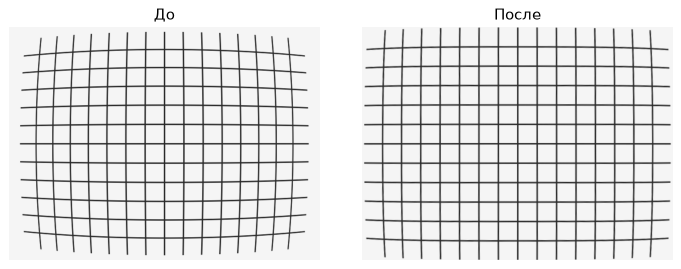

### Посчитаем ошибку без готовой формулы-функции

Начнём с двух точек. `np.array` создаёт массив из списка строк, `dtype=float` допускает дробные значения и отрицательные разности. Строка — точка, столбцы — x/y. Вычитание массивов происходит по соответствующим элементам: первая точка сравнивается с первой, вторая со второй.

In [ ]:
observed_demo = np.array([[3,4],[10,10]], dtype=float)
predicted_demo = np.array([[0,0],[10,10]], dtype=float)
delta = observed_demo - predicted_demo
print(delta)

У первой точки ошибки по координатам 3 и 4, расстояние до прогноза 5. У второй точки ошибка нулевая. `**2` возводит каждую разность в квадрат; `.sum(axis=1)` складывает два квадрата внутри каждой строки. Без указания оси мы сложили бы сразу все точки.

In [ ]:
squared = delta ** 2
squared_distances = squared.sum(axis=1)
print(squared)
print(squared_distances)

`.mean()` усредняет полученные квадраты расстояний, `np.sqrt` извлекает корень. Это RMS ошибки в пикселях. В нашем примере sqrt((25+0)/2) ≈ 3.54. Это не среднее двух расстояний (5+0)/2 = 2.5: большой промах сильнее влияет на RMS.

In [ ]:
mean_squared_distance = squared_distances.mean()
rms_demo = np.sqrt(mean_squared_distance)
print(rms_demo)

### Повторим на настоящих измерениях учебной доски

Соберём уже разобранные шаги в функцию `reprojection_rms`. Она принимает два массива одинаковой формы (число точек,2) и возвращает одно число. `return` отдаёт вычисленное значение. Из обоих наборов берём одинаковый индекс кадра — иначе сравним разные ракурсы.

In [ ]:
def reprojection_rms(observed, predicted):
    delta = observed - predicted
    squared = delta ** 2
    squared_distances = squared.sum(axis=1)
    mean_squared_distance = squared_distances.mean()
    return np.sqrt(mean_squared_distance)

observed = observed_all[0]
predicted = predicted_all[0]
base_error = reprojection_rms(observed, predicted)
print(frame_names[0], base_error)

Эта ошибка получена на кадре, участвовавшем в подборе модели. Она показывает согласование с измерениями, а не точность на любой будущей фотографии. Маленькое число не отменяет необходимости независимой проверки.

### ✏️ Ваш ход — один неверный угол

`.copy()` создаёт независимую копию массива. Создайте `bad_points = observed.copy()`. Запись `bad_points[0,0] += 20` добавит 20 к x первой точки: `+=` означает «прибавить к прежнему значению». Остальные координаты и прогноз не меняйте. Получите `bad_error` через разобранную функцию. Сначала предскажите, вырастет или уменьшится RMS. Объясните, почему это не повторная калибровка.

Перед изменением приведите копию координат к форме N×2 через `.reshape(-1, 2)`: версии OpenCV могут возвращать N×1×2 или N×2. Тогда x первой точки — `[0, 0]`; смысл опыта от формы хранения не меняется.


In [ ]:
# ✏️ ваш код здесь

In [ ]:
check('02.2.3', base_error, bad_error)

**Мой вывод:** какая координата изменена, какие два числа получились и что осталось неизменным. …

### Сравним ракурсы

Пустой список `errors` будет хранить одно число на кадр. `range(len(frame_names))` даёт его индексы; `.append` добавляет очередную ошибку. `np.argmax` вернёт позицию наибольшего числа — по ней выберем имя. Затем `plt.imread` прочитает PNG, `imshow` покажет его, `title` добавит подпись, `show` завершит вывод. Числа камеры не меняем.

In [ ]:
errors = []
for index in range(len(frame_names)):
    error = reprojection_rms(observed_all[index], predicted_all[index])
    errors.append(error)
worst = np.argmax(errors)
print(frame_names[worst], errors[worst])
worst_image = plt.imread(CAMERA_DIR / frame_names[worst])
plt.imshow(worst_image)
plt.title('Наибольший RMS среди предоставленных кадров')
plt.show()

**Самостоятельный опыт, 5–8 минут.** Возьмите другой индекс кадра, посчитайте его ошибку. На копии сдвиньте одну координату на 5, затем на 10 пикселей: для каждой пробы начинайте с исходной копии. Сохраните два результата и объяснение. Почему кадр с максимальным RMS нельзя объявлять непригодным без обсуждения масштаба ошибки и условий?

Сохраните тетрадь с пометкой «анализ предоставленной калибровки». Самостоятельно выполнены расчёт ошибки, сравнение и опыт с измерением. Детектор углов, подбор параметров и коррекция в этом маршруте были демонстрацией; для программной части ЛР1 вернитесь к основному маршруту в доступной среде по договорённости с преподавателем. Студентам не нужно устанавливать OpenCV во время этой пары. Уже выполненные проекция и EXIF из 02.1 остаются вашим результатом.